# 03 · Este orçamento vai fechar? (classificação)

**Pergunta de negócio:** *quais orçamentos têm mais chance de virar serviço, e o que a empresa pode fazer para
aumentar essa chance?*

Cada orçamento custa tempo: atendimento, às vezes uma visita para medir, cálculo e envio. Cerca de **4 em cada 10
orçamentos não fecham**. Um modelo que estime a chance de fechamento serve a dois usos:
1. **Priorizar:** retornar primeiro para os orçamentos pendentes com maior chance de fechar.
2. **Entender o que faz fechar:** quais fatores sob controle da empresa (prazo de resposta, visita técnica, desconto)
   realmente fazem diferença, separando o efeito de cada um.

## Por que classificação?

A resposta é **sim/não** (fechou ou não fechou), e existe histórico com a resposta certa: os orçamentos já
decididos. É um problema **supervisionado de classificação binária**.

## Algoritmos comparados

| Algoritmo | Por que testar |
|---|---|
| Baseline ("sempre fecha") | Referência mínima. Qualquer modelo precisa ser melhor que chutar a classe mais comum |
| **Regressão Logística** | Simples e **interpretável**: cada variável vira um "multiplicador de chance" (*odds ratio*) |
| Random Forest | Captura interações e efeitos não lineares automaticamente |
| Gradient Boosting | Em geral o mais preciso para dados tabulares |

**Regra de escolha:** se os modelos complexos não forem claramente melhores que a Regressão Logística, fica a
Logística, porque é mais fácil de explicar e de usar no dia a dia (princípio da parcimônia).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo_graficos as eg

eg.aplicar_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
DIR_PROC = RAIZ / "dados" / "processed"

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder

from preparar_dados import ler_processados

## 1. Preparação

### Variáveis usadas

Só entra informação **conhecida no momento em que o orçamento é enviado**:

| Variável | Tipo | Descrição |
|---|---|---|
| `origem_contato` | categórica | Como o cliente chegou (Google, indicação, Instagram…) |
| `segmento` | categórica | Segmento do cliente, descoberto no notebook 02 |
| `tipo_servico`, `tipo_imovel`, `cidade` | categóricas | O que foi pedido e onde |
| `log_valor_referencia` | numérica | Tamanho do orçamento (quantidade × preço de tabela, em log) |
| `desconto_pct` | numérica | Desconto oferecido (%) |
| `prazo_retorno_dias` | numérica | Dias entre o pedido e o envio do orçamento |
| `visita_tecnica` | 0/1 | Houve visita para medir? |
| `cliente_recorrente` | 0/1 | O cliente já tinha fechado algum serviço **antes** deste orçamento? |
| `preco_a_combinar` | 0/1 | O orçamento foi enviado sem preço definido? |

### Cuidado com vazamento de dados (*data leakage*)

Foram **excluídas** variáveis que só existem *depois* que o orçamento fecha e que, por isso, "entregariam a resposta":
`data_execucao`, `status`, fotos do serviço e chamados de manutenção. Um modelo treinado com elas teria
acerto altíssimo no teste e seria inútil na prática.

In [2]:
dados = ler_processados()
segmentos = pd.read_csv(DIR_PROC / "segmentos.csv")
orc = dados["orcamentos"].merge(segmentos, on="id_cliente", how="left")
orc["log_valor_referencia"] = np.log(orc["valor_referencia"])

NUMERICAS = ["log_valor_referencia", "desconto_pct", "prazo_retorno_dias"]
BINARIAS = ["visita_tecnica", "cliente_recorrente", "preco_a_combinar"]
CATEGORICAS = ["origem_contato", "segmento", "tipo_servico", "tipo_imovel", "cidade"]
VARIAVEIS = NUMERICAS + BINARIAS + CATEGORICAS

decididos = orc[orc["fechou"].notna()].copy()
decididos["fechou"] = decididos["fechou"].astype(int)
pendentes = orc[orc["situacao"] == "pendente"].copy()
print(f"Orçamentos decididos (treino/teste): {len(decididos)}  |  pendentes (para pontuar): {len(pendentes)}")
print(f"Taxa de fechamento: {decididos['fechou'].mean():.1%}  -> classes razoavelmente equilibradas")

Orçamentos decididos (treino/teste): 1565  |  pendentes (para pontuar): 35
Taxa de fechamento: 58.9%  -> classes razoavelmente equilibradas


### Separação treino × teste: **por tempo**, não aleatória

O modelo será usado para prever orçamentos **futuros**. Por isso o teste simula exatamente isso: o treino usa os
orçamentos de **2024–2025** e o teste os de **2026**, que o modelo nunca viu. Uma divisão aleatória misturaria
passado e futuro e tenderia a superestimar o desempenho.

In [3]:
CORTE = pd.Timestamp("2026-01-01")
treino = decididos[decididos["data_orcamento"] < CORTE]
teste = decididos[decididos["data_orcamento"] >= CORTE]
X_treino, y_treino = treino[VARIAVEIS], treino["fechou"]
X_teste, y_teste = teste[VARIAVEIS], teste["fechou"]

pd.DataFrame({
    "período": ["2024–2025", "2026 (jan–set)"],
    "orçamentos": [len(treino), len(teste)],
    "taxa de fechamento": [f"{y_treino.mean():.1%}", f"{y_teste.mean():.1%}"],
}, index=["treino", "teste"])

,período,orçamentos,taxa de fechamento
treino,2024–2025,1168,58.2%
teste,2026 (jan–set),397,61.0%


**Pré-processamento** (dentro de um `Pipeline`, para que nada do teste "vaze" para o treino):
- Numéricas: valores ausentes (quantidade inválida) recebem a mediana **do treino**.
- Categóricas: *one-hot encoding*. Uma categoria de referência é retirada de cada variável (ex.: origem = Google),
  para que os coeficientes da Logística sejam lidos como "em relação ao Google".

In [4]:
REFERENCIAS = {"origem_contato": "Google", "segmento": "Residencial econômico",
               "tipo_servico": "Forro Drywall", "tipo_imovel": "residencial", "cidade": "São João da Boa Vista"}

def preprocessador():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUMERICAS),
        ("bin", "passthrough", BINARIAS),
        ("cat", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(drop=[REFERENCIAS[c] for c in CATEGORICAS], handle_unknown="ignore",
                          sparse_output=False)), CATEGORICAS),
    ], verbose_feature_names_out=False)

modelos = {
    "Baseline (sempre fecha)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=5000),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=10, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                                        random_state=42),
}
pipelines = {nome: Pipeline([("prep", preprocessador()), ("modelo", m)]) for nome, m in modelos.items()}

## 2. Treino e avaliação

**Métricas:**
- **AUC (ROC):** de 0,5 (sorteio) a 1 (perfeito). Mede se o modelo dá nota maior aos orçamentos que fecham. É a
  métrica principal, porque o uso real é **ordenar** os orçamentos por chance de fechar.
- **Precisão:** dos que o modelo disse "vai fechar", quantos fecharam.
- **Recall:** dos que fecharam, quantos o modelo identificou.
- **F1:** equilíbrio entre precisão e recall.

Primeiro, **validação cruzada (5 partes) dentro do treino**, para ver a estabilidade de cada modelo:

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_cv = {}
for nome, pipe in pipelines.items():
    auc = cross_val_score(pipe, X_treino, y_treino, cv=cv, scoring="roc_auc")
    resultados_cv[nome] = {"AUC média (CV)": auc.mean(), "desvio": auc.std()}
pd.DataFrame(resultados_cv).T.round(3)

,AUC média (CV),desvio
Baseline (sempre fecha),0.50,0.00
Regressão Logística,0.73,0.04
Random Forest,0.73,0.02
Gradient Boosting,0.72,0.03


Depois, cada modelo é treinado com todo o período 2024–2025 e avaliado **uma única vez** no teste (2026):

In [6]:
resultados = {}
probabilidades = {}
for nome, pipe in pipelines.items():
    pipe.fit(X_treino, y_treino)
    prob = pipe.predict_proba(X_teste)[:, 1]
    pred = (prob >= 0.5).astype(int)
    probabilidades[nome] = prob
    resultados[nome] = {
        "AUC": roc_auc_score(y_teste, prob),
        "Acurácia": accuracy_score(y_teste, pred),
        "Precisão": precision_score(y_teste, pred, zero_division=0),
        "Recall": recall_score(y_teste, pred),
        "F1": f1_score(y_teste, pred),
    }
tabela_teste = pd.DataFrame(resultados).T.round(3)
tabela_teste

,AUC,Acurácia,Precisão,Recall,F1
Baseline (sempre fecha),0.50,0.61,0.61,1.00,0.76
Regressão Logística,0.74,0.70,0.70,0.88,0.78
Random Forest,0.70,0.69,0.68,0.91,0.78
Gradient Boosting,0.68,0.66,0.68,0.81,0.74


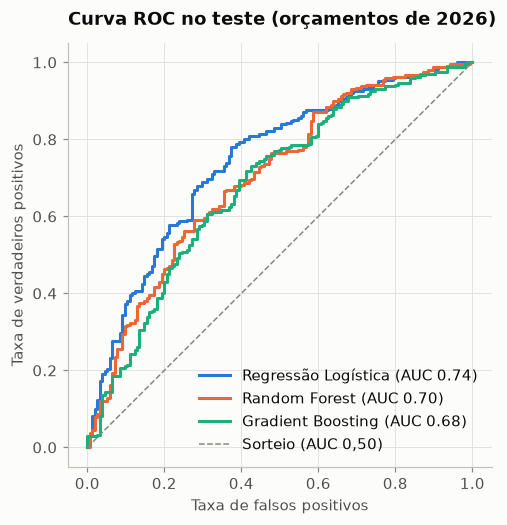

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for i, nome in enumerate(["Regressão Logística", "Random Forest", "Gradient Boosting"]):
    fpr, tpr, _ = roc_curve(y_teste, probabilidades[nome])
    ax.plot(fpr, tpr, color=eg.CORES[i], label=f"{nome} (AUC {resultados[nome]['AUC']:.2f})")
ax.plot([0, 1], [0, 1], color=eg.TINTA_SUAVE, linestyle="--", linewidth=1, label="Sorteio (AUC 0,50)")
ax.set_title("Curva ROC no teste (orçamentos de 2026)")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.set_aspect("equal")
ax.legend(loc="lower right")
plt.show()

**Escolha: Regressão Logística.**
- Na validação cruzada os três modelos empatam (AUC ~0,73). No teste de 2026, a Logística foi a melhor (0,74);
  Random Forest (0,70) e Gradient Boosting (0,68) perderam desempenho ao prever um período novo, sinal de que
  parte do que "aprenderam" a mais era ruído.
- Ela supera o baseline nas métricas que importam: AUC de 0,74 contra 0,50 e acurácia de 70% contra 61%.
- **Atenção ao F1 do baseline (0,76).** Ele é alto só porque o baseline diz "fecha" para todos (recall de 100%).
  Por isso o F1 sozinho enganaria aqui, e o AUC é a métrica principal.
- **Um AUC de 0,74 é um desempenho moderado a bom.** A decisão do cliente tem muito de imprevisível (orçamento da
  concorrência, mudança de planos), então o modelo não serve para "adivinhar" cada caso. Ele serve para
  **priorizar** e para **entender os fatores**, e nas duas coisas funciona bem, como mostram as próximas seções.

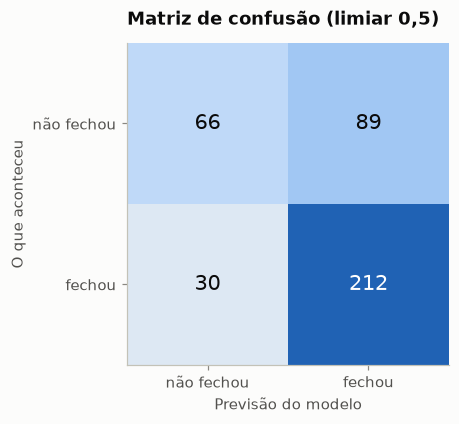

In [8]:
modelo = pipelines["Regressão Logística"]
prob_teste = probabilidades["Regressão Logística"]
matriz = confusion_matrix(y_teste, (prob_teste >= 0.5).astype(int))

fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.imshow(matriz, cmap=eg.SEQUENCIAL, vmin=0, vmax=matriz.max() * 1.3)
rotulos = ["não fechou", "fechou"]
ax.set_xticks([0, 1], rotulos)
ax.set_yticks([0, 1], rotulos)
ax.set_xlabel("Previsão do modelo")
ax.set_ylabel("O que aconteceu")
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, matriz[i, j], ha="center", va="center", fontsize=14,
                color="white" if matriz[i, j] > matriz.max() * 0.6 else eg.TINTA)
ax.set_title("Matriz de confusão (limiar 0,5)")
plt.show()

### O modelo serve para priorizar?

Na prática, a empresa vai **ordenar** os orçamentos pela chance prevista. O teste abaixo divide os orçamentos de
2026 em 5 faixas (quintis) da nota do modelo e mostra quanto cada faixa realmente fechou:

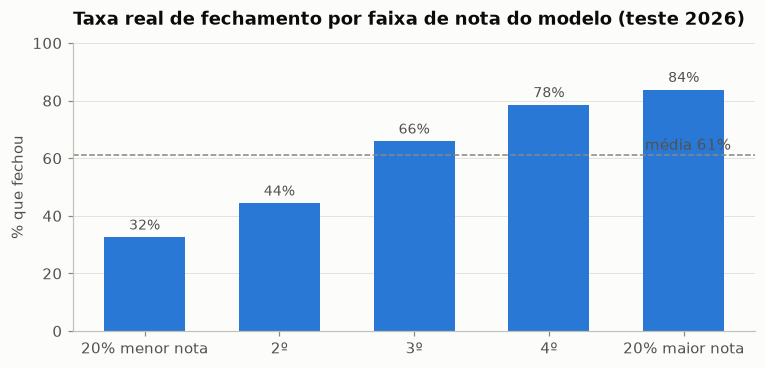

Faixa de maior nota fecha 84%; faixa de menor nota fecha 32% (2.6x mais)


In [9]:
faixas = pd.qcut(prob_teste, 5, labels=["20% menor nota", "2º", "3º", "4º", "20% maior nota"])
por_faixa = pd.Series(y_teste.values).groupby(faixas, observed=True).mean()

fig, ax = plt.subplots(figsize=(8, 3.4))
barras = ax.bar(por_faixa.index.astype(str), por_faixa.values * 100, color=eg.CORES[0], width=0.6)
eg.rotular_barras(ax, barras, "{:.0f}%")
ax.axhline(y_teste.mean() * 100, color=eg.TINTA_SUAVE, linestyle="--", linewidth=1)
ax.text(4.35, y_teste.mean() * 100 + 2, f"média {y_teste.mean():.0%}", color=eg.TINTA_SECUNDARIA, ha="right")
ax.set_ylim(0, 100)
ax.set_ylabel("% que fechou")
ax.set_title("Taxa real de fechamento por faixa de nota do modelo (teste 2026)")
ax.grid(axis="x", visible=False)
plt.show()
print(f"Faixa de maior nota fecha {por_faixa.iloc[-1]:.0%}; faixa de menor nota fecha {por_faixa.iloc[0]:.0%} "
      f"({por_faixa.iloc[-1] / por_faixa.iloc[0]:.1f}x mais)")

## 3. Interpretação: o que faz um orçamento fechar?

### a) Importância de cada variável (permutação)

Embaralha-se uma variável por vez no teste e mede-se quanto o AUC cai. Quanto maior a queda, mais o modelo depende
dela. É um método que vale para qualquer modelo.

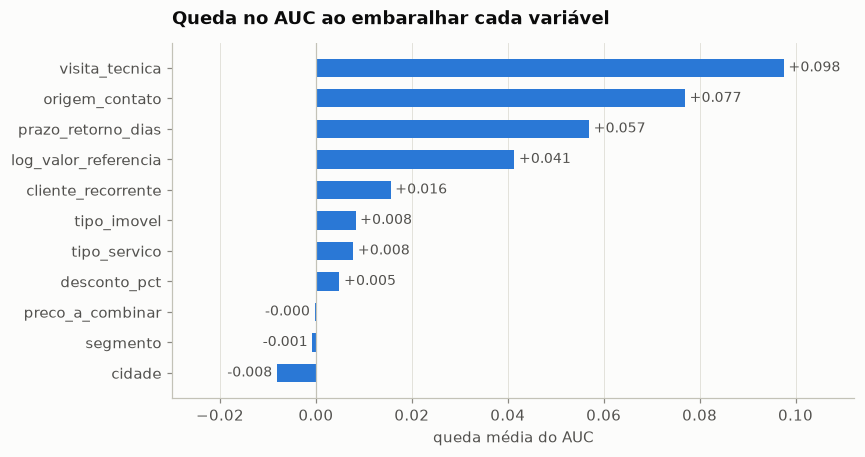

In [10]:
imp = permutation_importance(modelo, X_teste, y_teste, scoring="roc_auc", n_repeats=30, random_state=42)
importancia = pd.Series(imp.importances_mean, index=VARIAVEIS).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
barras = ax.barh(importancia.index, importancia.values, color=eg.CORES[0], height=0.6)
eg.rotular_barras(ax, barras, "{:+.3f}")
ax.set_xlim(-0.03, importancia.max() * 1.15)
ax.axvline(0, color=eg.EIXO, linewidth=0.8)
ax.set_title("Queda no AUC ao embaralhar cada variável")
ax.set_xlabel("queda média do AUC")
ax.grid(axis="y", visible=False)
plt.show()

### b) Multiplicadores de chance (*odds ratio*) da Regressão Logística

Cada coeficiente da Logística diz por quanto a **chance** de fechar é multiplicada quando a variável muda,
**mantendo todas as outras iguais**. Valores acima de 1 aumentam a chance; abaixo de 1, diminuem. Para as
categóricas, a comparação é com a categoria de referência (ex.: origem = Google).

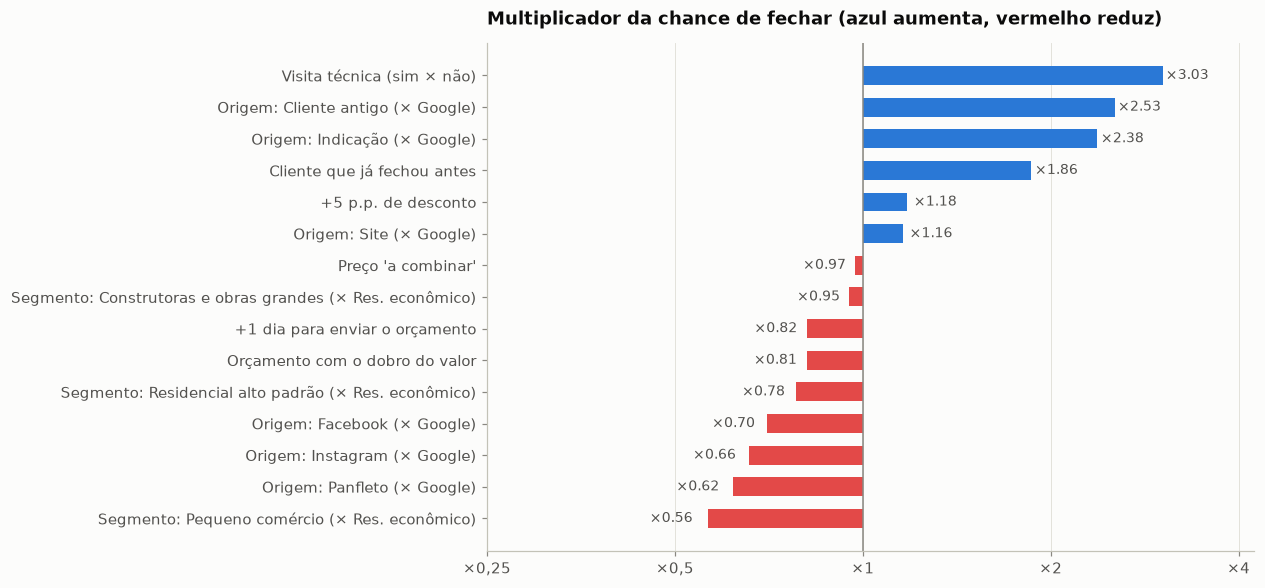

In [11]:
coef = pd.Series(modelo.named_steps["modelo"].coef_[0],
                 index=modelo.named_steps["prep"].get_feature_names_out())

efeitos = {
    "Visita técnica (sim × não)": np.exp(coef["visita_tecnica"]),
    "Cliente que já fechou antes": np.exp(coef["cliente_recorrente"]),
    "+1 dia para enviar o orçamento": np.exp(coef["prazo_retorno_dias"]),
    "+5 p.p. de desconto": np.exp(5 * coef["desconto_pct"]),
    "Orçamento com o dobro do valor": np.exp(np.log(2) * coef["log_valor_referencia"]),
    "Preço 'a combinar'": np.exp(coef["preco_a_combinar"]),
}
for c in coef.index:
    if c.startswith("origem_contato_"):
        efeitos[f"Origem: {c.removeprefix('origem_contato_')} (× Google)"] = np.exp(coef[c])
    if c.startswith("segmento_"):
        efeitos[f"Segmento: {c.removeprefix('segmento_')} (× Res. econômico)"] = np.exp(coef[c])
efeitos = pd.Series(efeitos).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
cores = [eg.CORES[0] if v >= 1 else eg.CORES[7] for v in efeitos.values]
ax.barh(efeitos.index, efeitos.values - 1, left=1, color=cores, height=0.6)
for i, v in enumerate(efeitos.values):
    ax.text(v + (0.03 if v >= 1 else -0.03), i, f"×{v:.2f}", va="center",
            ha="left" if v >= 1 else "right", fontsize=9, color=eg.TINTA_SECUNDARIA)
ax.axvline(1, color=eg.TINTA_SUAVE, linewidth=1)
ax.set_xscale("log")
ax.set_xlim(efeitos.min() * 0.7, efeitos.max() * 1.4)
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["×0,25", "×0,5", "×1", "×2", "×4"])
ax.minorticks_off()
ax.set_title("Multiplicador da chance de fechar (azul aumenta, vermelho reduz)")
ax.grid(axis="y", visible=False)
plt.show()

### c) Simulação: prazo de resposta × visita técnica

Para cada orçamento de 2026, o modelo recalcula a chance de fechar mudando **só** o prazo de envio (0 a 7 dias)
e a visita técnica, e tira a média. Isso mostra o efeito isolado das duas alavancas que a empresa controla:

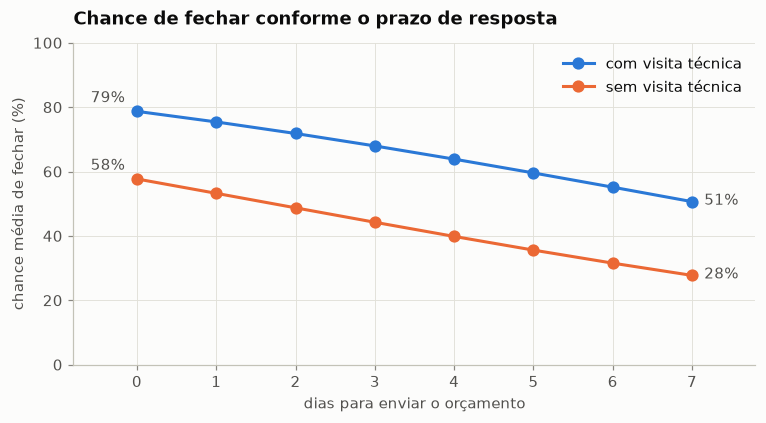

In [12]:
dias = range(0, 8)
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (visita, rotulo) in enumerate([(1, "com visita técnica"), (0, "sem visita técnica")]):
    chance = [modelo.predict_proba(X_teste.assign(prazo_retorno_dias=d, visita_tecnica=visita))[:, 1].mean()
              for d in dias]
    ax.plot(list(dias), np.array(chance) * 100, marker="o", color=eg.CORES[i], label=rotulo)
    ax.annotate(f"{chance[0]:.0%}", (0, chance[0] * 100), textcoords="offset points", xytext=(-8, 6),
                ha="right", color=eg.TINTA_SECUNDARIA)
    ax.annotate(f"{chance[-1]:.0%}", (7, chance[-1] * 100), textcoords="offset points", xytext=(8, -2),
                color=eg.TINTA_SECUNDARIA)
ax.set_ylim(0, 100)
ax.set_xlim(-0.8, 7.8)
ax.set_xlabel("dias para enviar o orçamento")
ax.set_ylabel("chance média de fechar (%)")
ax.set_title("Chance de fechar conforme o prazo de resposta")
ax.legend(loc="upper right")
plt.show()

### d) E o desconto?

A Logística supõe um efeito em linha reta. Aqui vale olhar os dados diretamente, por faixa de desconto oferecido:

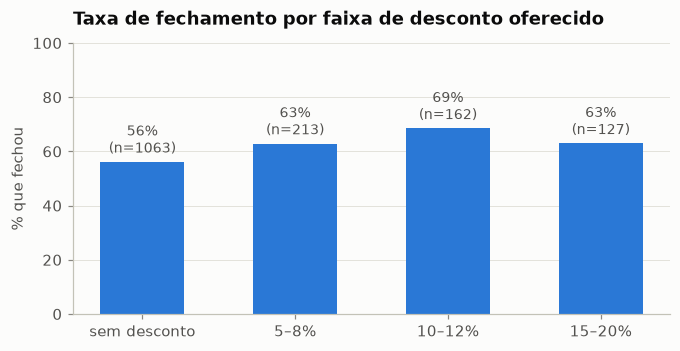

In [13]:
faixas_desc = pd.cut(decididos["desconto_pct"], [-1, 0, 8, 12, 20], labels=["sem desconto", "5–8%", "10–12%", "15–20%"])
por_desc = decididos.groupby(faixas_desc, observed=True)["fechou"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7, 3.2))
barras = ax.bar(por_desc.index.astype(str), por_desc["mean"] * 100, color=eg.CORES[0], width=0.55)
ax.bar_label(barras, labels=[f"{m:.0%}\n(n={int(n)})" for m, n in por_desc.values], padding=3,
             color=eg.TINTA_SECUNDARIA, fontsize=9)
ax.set_ylim(0, 100)
ax.set_ylabel("% que fechou")
ax.set_title("Taxa de fechamento por faixa de desconto oferecido")
ax.grid(axis="x", visible=False)
plt.show()

O desconto ajuda **até cerca de 10–12%**: o fechamento sobe de 56% (sem desconto) para 69%. Já **15–20% fecha
menos que 10–12%**, ou seja, desconto acima de ~12% só reduz a margem. A Logística, que supõe um efeito em linha
reta, não captura esse "teto". É uma limitação conhecida do modelo, e por isso a regra prática vem desta
comparação direta. Por ser descritiva, ela pode misturar outros efeitos (perfis diferentes recebem descontos diferentes).

## 4. Aplicação: priorizar os orçamentos pendentes

Os orçamentos ainda sem resposta (status `orçado`) são pontuados pelo modelo final, agora retreinado com **todos**
os orçamentos decididos. A coluna "chance com visita" simula o ganho de agendar uma visita quando ela ainda
não aconteceu:

In [14]:
final = Pipeline([("prep", preprocessador()), ("modelo", LogisticRegression(max_iter=5000))])
final.fit(decididos[VARIAVEIS], decididos["fechou"])

pendentes["chance_fechar"] = final.predict_proba(pendentes[VARIAVEIS])[:, 1]
pendentes["chance_com_visita"] = final.predict_proba(pendentes[VARIAVEIS].assign(visita_tecnica=1))[:, 1]

def acao(linha):
    if linha["chance_fechar"] >= 0.7:
        return "Ligar hoje: alta chance"
    if linha["visita_tecnica"] == 0 and linha["chance_com_visita"] - linha["chance_fechar"] >= 0.1:
        return "Oferecer visita técnica"
    if linha["chance_fechar"] < 0.4:
        return "Baixa prioridade"
    return "Retornar esta semana"

pendentes["ação sugerida"] = pendentes.apply(acao, axis=1)
lista = (pendentes.sort_values("chance_fechar", ascending=False)
         [["id_servico", "segmento", "tipo_servico", "valor_referencia", "prazo_retorno_dias",
           "visita_tecnica", "chance_fechar", "chance_com_visita", "ação sugerida"]])
lista.assign(
    valor_referencia=lista["valor_referencia"].map(lambda v: f"R$ {v:,.0f}".replace(",", ".") if pd.notna(v) else "–"),
    visita_tecnica=lista["visita_tecnica"].map({1: "sim", 0: "não"}),
    chance_fechar=lista["chance_fechar"].map("{:.0%}".format),
    chance_com_visita=lista["chance_com_visita"].map("{:.0%}".format),
).set_index("id_servico")

,segmento,tipo_servico,valor_referencia,prazo_retorno_dias,visita_tecnica,chance_fechar,chance_com_visita,ação sugerida
id_servico,,,,,,,,
1590,Construtoras e obras grandes,Gesso Liso,R$ 106,1,sim,96%,96%,Ligar hoje: alta chance
1592,Construtoras e obras grandes,Sanca,R$ 3.262,3,sim,90%,90%,Ligar hoje: alta chance
1591,Residencial alto padrão,Gesso 3D,R$ 2.192,5,sim,88%,88%,Ligar hoje: alta chance
1583,Construtoras e obras grandes,Sanca,R$ 2.909,0,não,86%,95%,Ligar hoje: alta chance
1575,Residencial alto padrão,Moldura de Gesso,R$ 118,0,sim,85%,85%,Ligar hoje: alta chance
1587,Residencial alto padrão,Moldura de Gesso,R$ 214,0,não,84%,94%,Ligar hoje: alta chance
1570,Construtoras e obras grandes,Divisória Drywall,R$ 30.172,1,sim,83%,83%,Ligar hoje: alta chance
1569,Residencial alto padrão,Moldura de Gesso,R$ 28,4,sim,83%,83%,Ligar hoje: alta chance
1580,Residencial alto padrão,Boiserie,R$ 2.902,1,sim,82%,82%,Ligar hoje: alta chance


In [15]:
pendentes["ação sugerida"].value_counts().to_frame("orçamentos pendentes")

,orçamentos pendentes
ação sugerida,
Ligar hoje: alta chance,14
Retornar esta semana,12
Oferecer visita técnica,7
Baixa prioridade,2


In [16]:
coef_final = pd.Series(final.named_steps["modelo"].coef_[0], index=final.named_steps["prep"].get_feature_names_out())
metricas = {
    "modelo_escolhido": "Regressão Logística",
    "teste": tabela_teste.to_dict("index"),
    "cv": {k: {kk: round(vv, 3) for kk, vv in v.items()} for k, v in resultados_cv.items()},
    "taxa_quintil_maior": round(float(por_faixa.iloc[-1]), 3),
    "taxa_quintil_menor": round(float(por_faixa.iloc[0]), 3),
    "odds": {k: round(float(v), 2) for k, v in efeitos.items()},
    "pendentes": int(len(pendentes)),
    "acoes": pendentes["ação sugerida"].value_counts().to_dict(),
}
_ = (DIR_PROC / "metricas_classificacao.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2))

## Insights e recomendações

1. **A visita técnica é a alavanca nº 1.** Ela multiplica a chance de fechar por **~3** e é a variável mais
   importante do modelo. Na simulação, um orçamento enviado no mesmo dia passa de **58% para 79%** de chance com visita.
   → Oferecer visita sempre que possível, principalmente em obras médias e grandes.
2. **Velocidade fecha negócio.** Cada dia de demora para enviar o orçamento reduz a chance em **~18%** (×0,82).
   Enviar em 7 dias em vez de no mesmo dia derruba a chance de 79% para 51%, mesmo com visita.
   → Meta de **orçamento enviado em até 48 h**, com modelo de orçamento padronizado para agilizar.
3. **Indicação e cliente antigo fecham mais que o dobro** (×2,4 e ×2,5 em relação ao Google). Facebook, Instagram
   e panfleto fecham menos (×0,62 a ×0,70). Isso reforça o programa de indicação sugerido no notebook 02. Os contatos
   de redes sociais são mais "frios", e responder rápido pesa ainda mais para eles.
4. **Desconto: até 10%.** Acima de ~12% não aumenta o fechamento e só reduz a margem.
5. **O pequeno comércio fecha pouco mesmo com o processo igual** (×0,56 em relação ao residencial econômico, já
   descontando visita, prazo e origem). A baixa conversão do segmento (44%) não é culpa do atendimento:
   provavelmente ele cota com vários concorrentes. → Diferenciar a proposta (prazo de execução garantido, obra fora
   do horário comercial) e investigar com a equipe comercial.
   *(O segmento quase não aparece na importância por permutação porque boa parte da informação já está na origem do
   contato, que é muito ligada ao segmento, como visto no notebook 02.)*
6. **A priorização funciona.** No teste, os 20% de orçamentos com maior nota fecharam **84%**, contra **32%** dos 20%
   com menor nota (**2,6×**). Dos 35 orçamentos pendentes hoje, **14 são para ligar hoje** e em **7 vale oferecer
   visita técnica**.